# 30 — Classificatori variazionali quantistici sullo split comune

I modelli dei notebook `10_…_original` (Comparing, 4 qubit) e `11_…_original` (QAOA v2, 8 qubit), riportati sullo **stesso split, stesso test e stesse metriche** delle baseline classiche (notebook 20).

| Modello | Qubit / feature | Circuito | Lettura | Ottimizzatore |
|---|---|---|---|---|
| QAOA RF-aware 8q | 8 | RZ · IsingZZ (accoppiamenti = correlazioni del train) · RX, 4 layer | affine σ(a·z+b) | Adam |
| VQE-inspired 4q | 4 (SelectKBest) | StronglyEntanglingLayers, 2 layer | p = (1−z)/2 | Adam |
| QAOA-inspired 4q | 4 | RZ(γx) · IsingZZ(γ) · RX(2β), 2 layer | p = (1−z)/2 | Adam |
| VQS-inspired 4q | 4 | come VQE | p = (1−z)/2 | gradiente naturale diagonale |
| VQE-inspired 4q + lettura affine | 4 | come VQE | affine | Adam (**ablation**) |

Differenze rispetto ai notebook originali, uguali per tutti i modelli: minibatch valutati in un'unica chiamata (broadcasting: stesso risultato, molto più veloce) e modello finale scelto con la migliore **AUROC di validazione**. Il test non è mai usato durante l'addestramento. 5 seed, 5.000 righe di training come le baseline `train`.

In [1]:
import sys, time, json
from pathlib import Path
REPO = Path.cwd()
while not (REPO / 'qdetect').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pennylane as qml
import qdetect as qd
from qdetect import quantum as Q, baselines as B
print('PennyLane', qml.__version__)

split = qd.load_split(REPO / 'splits/split_files_v2.npz')
P8 = qd.prepare(split, angle_scale=2.0)              # 8 feature, come QAOA v2
P4 = qd.prepare(split, k_best=4, angle_scale=3.0)    # 4 feature, come Comparing
print('feature 4 qubit:', P4.features)
EDGES, COUPLINGS = Q.edges_from_correlation(P8.X_train)
print(len(EDGES), 'archi:', EDGES)

SEEDS = [42, 123, 2024, 2025, 2026]
RESULTS = REPO / 'results' / 'quantum_variational.csv'
OUT = REPO / 'results' / 'quantum_variational'
OUT.mkdir(parents=True, exist_ok=True)

PennyLane 0.45.1
feature 4 qubit: ['noise', 'total_gain_db', 'base_pwr_db', 'rssi']
15 archi: [(0, 1), (1, 2), (1, 3), (1, 4), (1, 5), (2, 3), (3, 4), (3, 5), (3, 6), (3, 7), (4, 5), (4, 6), (4, 7), (5, 6), (6, 7)]


In [2]:
ORIG_4Q = dict(steps=500, batch=16, lr=0.05, eval_every=20, patience=10, init_scale=0.08)
MODELS = {
    'QAOA RF-aware 8q': dict(P=P8, circuit=lambda: Q.qaoa_rf_aware(8, 4, EDGES, COUPLINGS), readout='affine',
                             optimizer='adam', steps=1200, batch=32, lr=0.015, eval_every=25, patience=12, init_scale=0.12),
    'VQE-inspired 4q': dict(P=P4, circuit=lambda: Q.vqe_sel(4, 2), readout='prob', optimizer='adam', **ORIG_4Q),
    'QAOA-inspired 4q': dict(P=P4, circuit=lambda: Q.qaoa_global(4, 2), readout='prob', optimizer='adam', **ORIG_4Q),
    'VQS-inspired 4q': dict(P=P4, circuit=lambda: Q.vqe_sel(4, 2), readout='prob', optimizer='qng_diag',
                            **{**ORIG_4Q, 'lr': 0.02}),
    'VQE-inspired 4q + lettura affine': dict(P=P4, circuit=lambda: Q.vqe_sel(4, 2), readout='affine',
                                             optimizer='adam', **ORIG_4Q),
}

## 1. Addestramento e valutazione

In [3]:
rows, histories, scores42 = [], {}, {}
t_all = time.time()
for name, cfg in MODELS.items():
    cfg = dict(cfg); P = cfg.pop('P'); circ = cfg.pop('circuit')()
    for seed in SEEDS:
        r = Q.train(circ, P.X_train, P.y_train, P.X_val, P.y_val, seed=seed, **cfg)
        histories[f'{name} | {seed}'] = r.history
        np.save(OUT / f"params_{name.replace(' ', '_')}_{seed}.npy", r.params)
        for es, (Xe, ye) in {'test': (P.X_test, P.y_test), **P.extra}.items():
            t0 = time.perf_counter(); s = Q.predict_score(r.params, circ, Xe, cfg['readout']); t_inf = time.perf_counter() - t0
            rows.append(qd.evaluate(name, ye, s, family='quantum', seed=seed, split=es, n_train=len(P.y_train),
                                    n_params=Q.n_trainable(circ, cfg['readout']), train_seconds=r.train_seconds,
                                    infer_seconds=t_inf, notes='train_set=train'))
            if seed == 42 and es == 'test':
                scores42[name] = s
        print(f"{name:34s} seed={seed:<5d} passi={r.steps_run:5d} (migliore {r.best_step:5d})  "
              f"val={r.best_val_auc:.4f}  test={rows[-2]['auroc']:.4f}  {r.train_seconds:6.0f}s", flush=True)
res = pd.DataFrame(rows)
res.to_csv(RESULTS, index=False)
(OUT / 'histories.json').write_text(json.dumps(histories))
print(f'totale {time.time()-t_all:.0f} s')

QAOA RF-aware 8q                   seed=42    passi= 1200 (migliore  1200)  val=0.9966  test=0.9118     136s


QAOA RF-aware 8q                   seed=123   passi= 1200 (migliore  1200)  val=0.9969  test=0.9233     136s


QAOA RF-aware 8q                   seed=2024  passi= 1200 (migliore  1150)  val=0.9965  test=0.9264     137s


QAOA RF-aware 8q                   seed=2025  passi= 1200 (migliore  1175)  val=0.9967  test=0.9284     135s


QAOA RF-aware 8q                   seed=2026  passi= 1200 (migliore  1100)  val=0.9962  test=0.9254     135s


VQE-inspired 4q                    seed=42    passi=  300 (migliore   100)  val=0.9560  test=0.7615       2s


... (16 outputs left out)

VQE-inspired 4q + lettura affine   seed=2024  passi=  440 (migliore   240)  val=0.9714  test=0.8217       4s


VQE-inspired 4q + lettura affine   seed=2025  passi=  340 (migliore   140)  val=0.9704  test=0.8160       3s


VQE-inspired 4q + lettura affine   seed=2026  passi=  500 (migliore   440)  val=0.9714  test=0.8218       4s


totale 789 s


## 2. Riepilogo e confronto con le baseline classiche (5.000 righe di training)

In [4]:
pd.set_option('display.width', 220)
cols = ['split', 'model', 'n_seeds', 'auroc_mean', 'auroc_std', 'f1_mean', 'pd_at_pfa_0.01_mean', 'pd_at_pfa_0.05_mean', 'train_seconds_mean']
q = B.summarize(res).assign(famiglia='quantistico')
base = pd.read_csv(REPO / 'results' / 'baselines_classical.csv')
base = base[base['notes'] == 'train_set=train']
c = B.summarize(base).assign(famiglia='classico')
params = pd.concat([res, base]).groupby('model')['n_params'].first()
table = pd.concat([q, c]).merge(params.rename('n_params'), left_on='model', right_index=True, how='left')
table = table.sort_values(['split', 'auroc_mean'], ascending=[True, False])
table[['famiglia', 'n_params'] + cols].round(4)

,famiglia,n_params,split,model,n_seeds,auroc_mean,auroc_std,f1_mean,pd_at_pfa_0.01_mean,pd_at_pfa_0.05_mean,train_seconds_mean
4,classico,NaN,test,Random Forest,5,0.9617,0.0003,0.8970,0.5059,0.7821,0.2412
0,classico,NaN,test,Gradient Boosting,5,0.9572,0.0000,0.9024,0.3500,0.7248,0.3464
5,classico,NaN,test,SVM RBF,1,0.9386,NaN,0.8848,0.1068,0.5696,0.0438
2,classico,6001.0,test,"MLP (100, 50)",5,0.9343,0.0038,0.8794,0.1687,0.5319,0.3099
0,quantistico,126.0,test,QAOA RF-aware 8q,5,0.9231,0.0066,0.8579,0.2186,0.5256,135.8737
3,classico,101.0,test,MLP small (10),5,0.9064,0.0079,0.8438,0.1601,0.4512,0.1926
1,classico,9.0,test,Logistic Regression,1,0.8949,NaN,0.8383,0.1452,0.3296,0.0110
3,quantistico,26.0,test,VQE-inspired 4q + lettura affine,5,0.8254,0.0112,0.7902,0.0339,0.2209,3.6908
2,quantistico,24.0,test,VQE-inspired 4q,5,0.7565,0.0082,0.7328,0.0548,0.1772,2.4790
4,quantistico,24.0,test,VQS-inspired 4q,5,0.7465,0.0065,0.7487,0.0793,0.1557,6.2737


## 3. Test di DeLong sul test di riferimento (seed 42)

In [5]:
P_std = qd.prepare(split)   # 8 feature standardizzate, come nel notebook 20
ref = {}
for name in ['Random Forest', 'MLP small (10)', 'Logistic Regression']:
    build, _ = B.MODELS[name]
    m = build(42).fit(P_std.X_train, P_std.y_train)
    ref[name] = B.score(m, P_std.X_test)[0]
y = P8.y_test
out = []
for qn, qs in scores42.items():
    for cn, cs in ref.items():
        out.append({'quantistico': qn, 'classico': cn, **qd.delong_test(y, qs, cs)})
pd.DataFrame(out).round(4)

,quantistico,classico,auroc_a,auroc_b,diff,z,p_value
0,QAOA RF-aware 8q,Random Forest,0.9118,0.9613,-0.0495,-15.8397,0.0000
1,QAOA RF-aware 8q,MLP small (10),0.9118,0.9135,-0.0017,-0.5876,0.5568
2,QAOA RF-aware 8q,Logistic Regression,0.9118,0.8949,0.0169,5.4600,0.0000
3,VQE-inspired 4q,Random Forest,0.7615,0.9613,-0.1998,-32.0221,0.0000
4,VQE-inspired 4q,MLP small (10),0.7615,0.9135,-0.1519,-26.1052,0.0000
5,VQE-inspired 4q,Logistic Regression,0.7615,0.8949,-0.1334,-24.1151,0.0000
6,QAOA-inspired 4q,Random Forest,0.5239,0.9613,-0.4374,-51.4422,0.0000
7,QAOA-inspired 4q,MLP small (10),0.5239,0.9135,-0.3896,-45.2921,0.0000
8,QAOA-inspired 4q,Logistic Regression,0.5239,0.8949,-0.3710,-42.7957,0.0000
9,VQS-inspired 4q,Random Forest,0.7462,0.9613,-0.2151,-32.1535,0.0000


## 4. Curve di validazione

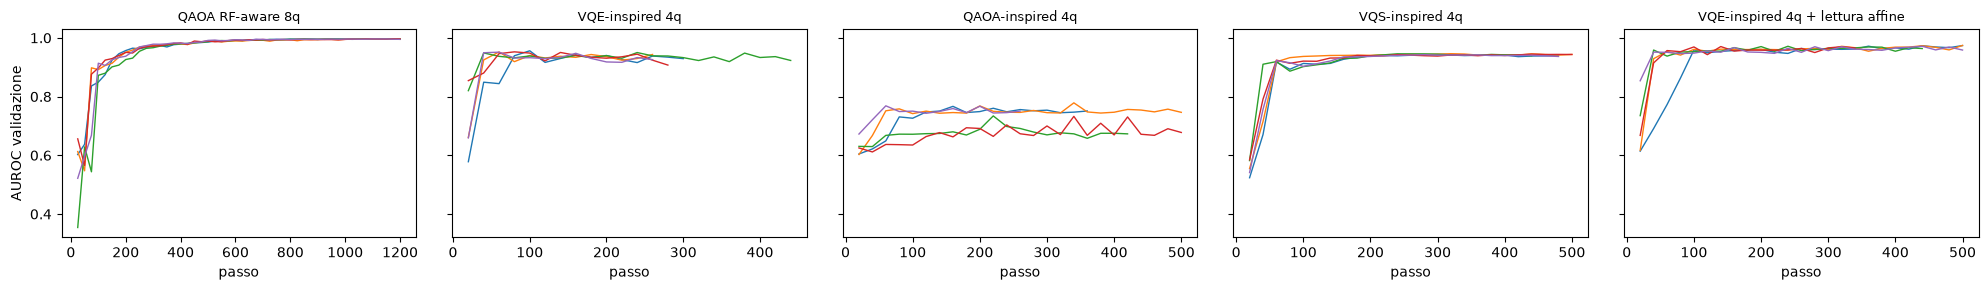

In [6]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(4 * len(MODELS), 3), sharey=True)
for ax, name in zip(axes, MODELS):
    for seed in SEEDS:
        h = histories[f'{name} | {seed}']
        ax.plot([p['step'] for p in h], [p['val_auc'] for p in h], lw=1)
    ax.set_title(name, fontsize=9); ax.set_xlabel('passo')
axes[0].set_ylabel('AUROC validazione')
plt.tight_layout(); plt.savefig(OUT / 'validation_curves.png', dpi=130); plt.show()